# 01 Diagnostic initial de la qualité des données

**Projet :** Life Expectancy (2000–2015)

**Objectif :** Identifier les problèmes de qualité des données
(valeurs manquantes, doublons, incohérences et valeurs atypiques)
afin de déterminer les traitements nécessaires avant les analyses. identifier et documenter les problèmes sans modifier les données.

**Référence Agile :** 

Epic 2 — Préparation initiale des données (LEP-2)

Story LEP-2 — Vérifier la qualité des données

### Travaux réalisés

- Vérification de la structure et des types de données.
- Identification des valeurs manquantes et des doublons.
- Contrôle de cohérence des variables.
- Détection des valeurs atypiques.
- Décision de préparation des données

### 1.1 Importation des librairies

In [ ]:
from pathlib import Path
import pandas as pd
import missingno as msno
import matplotlib.pyplot as plt

### 1.2 Importation du jeu de données

In [ ]:
# Définir le chemin du dossier des données
DATA_DIR = Path("../data")

# Importer le fichier CSV
df = pd.read_csv(DATA_DIR / "Life_Expectancy.csv")

# Controle du chargement
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


**Résultat du contrôle :** Le fichier `Life_Expectancy.csv` a été chargé avec succès. La vérification de la structure et de la qualité des données sera effectuée dans les sections suivantes.

### 1.2 Examen de la structure et des variables

In [ ]:
# Vérifier le nombre de ligne et colonnes du jeu de données
df.shape
print(f"Le jeu de donnée contient {df.shape[0]} lignes et {df.shape[1]} colonnes ")

Le jeu de donnée contient 2938 lignes et 22 colonnes 


In [ ]:
# Vérifier et lister les colonnes du jeu de données
print(df.columns.tolist())

['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years', ' thinness 5-9 years', 'Income composition of resources', 'Schooling']


In [ ]:
# Examiner la structure et les types des variables
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

Observations : Le jeu de données comprend trois catégories de variables : numériques discrètes, numériques continues et qualitatives. Leur définition et leur rôle dans l'analyse sont présentés dans le rapport. On note aussi la présence de valeurs manquantes sur certaines colonnes qui seront mieux analysés ensuite.

In [ ]:
# Vérifier les valeurs des variables pour mieux apprécier la définition proposée par Kaggle
df.describe()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.000000,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,2904.000000,2938.000000,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
mean,2007.518720,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,38.321247,42.035739,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,4.613841,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,20.044034,160.445548,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,2004.000000,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,19.300000,0.000000,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,2008.000000,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,43.500000,4.000000,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,2012.000000,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,56.200000,28.000000,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,99.000000,17.60000,99.000000,50.600000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000


In [ ]:
# Identifier le pays et l'année correspondant au maximum de décès infantiles
df.loc[df['infant deaths'].idxmax(), ['Country', 'Year', 'infant deaths']]

Country          India
Year              2001
infant deaths     1800
Name: 1200, dtype: object

In [ ]:
# Identifier le pays et l'année correspondant au maximum de Measles
df.loc[df['Measles '].idxmax(), ['Country', 'Year', 'Measles ']]

Country     Nigeria
Year           2000
Measles      212183
Name: 1908, dtype: object

In [ ]:
# Identifier le pays et l'année de la dépense maximale
df.loc[
    df['percentage expenditure'].idxmax(),
    ['Country', 'Year', 'percentage expenditure', 'GDP']
]

Country                   Switzerland
Year                             2014
percentage expenditure    19479.91161
GDP                       85814.58857
Name: 2522, dtype: object

In [ ]:
# Comparer les dépenses de santé et le PIB par habitant en 2014 pour le canada, l'inde et la suisse
df.loc[
    df['Country'].isin(['Switzerland', 'Canada', 'India'])
    & (df['Year'] == 2014),
    ['Country', 'Year', 'percentage expenditure', 'GDP']
]

,Country,Year,percentage expenditure,GDP
497,Canada,2014,102.190217,544.43376
1187,India,2014,86.521539,1573.11889
2522,Switzerland,2014,19479.911610,85814.58857


In [ ]:
# Examiner les valeurs économiques du Canada entre 2000 et 2015
df.loc[
    df['Country'] == 'Canada',
    ['Year', 'percentage expenditure', 'GDP']
].sort_values('Year')

,Year,percentage expenditure,GDP
511,2000,3787.494560,24124.16917
510,2001,3665.089703,23691.59472
509,2002,3895.856308,24167.84310
508,2003,4687.845565,28172.14883
507,2004,5513.329924,31979.87195
506,2005,6333.177967,36189.58838
505,2006,771.181769,4386.69948
504,2007,7946.743581,44544.52680
503,2008,8433.936814,46596.33599
502,2009,864.949930,4773.45436


In [ ]:
# Examiner le rapport entre les deux indicateurs économiques
canada = df.loc[df['Country'] == 'Canada',
                ['Year', 'percentage expenditure', 'GDP']].copy()

canada['ratio_pct'] = (
    canada['percentage expenditure'] / canada['GDP'] * 100
)

canada.sort_values('Year')

,Year,percentage expenditure,GDP,ratio_pct
511,2000,3787.494560,24124.16917,15.70
510,2001,3665.089703,23691.59472,15.47
509,2002,3895.856308,24167.84310,16.12
508,2003,4687.845565,28172.14883,16.64
507,2004,5513.329924,31979.87195,17.24
506,2005,6333.177967,36189.58838,17.50
505,2006,771.181769,4386.69948,17.58
504,2007,7946.743581,44544.52680,17.84
503,2008,8433.936814,46596.33599,18.10
502,2009,864.949930,4773.45436,18.12


In [ ]:
# Comparer le ratio calculé avec Total expenditure
canada = df.loc[
    df['Country'] == 'Canada',
    ['Year', 'percentage expenditure', 'GDP', 'Total expenditure']
].copy()

canada['ratio_pct'] = (
    canada['percentage expenditure'] / canada['GDP'] * 100
)

canada.sort_values('Year').round(2)

,Year,percentage expenditure,GDP,Total expenditure,ratio_pct
511,2000,3787.49,24124.17,8.67,15.70
510,2001,3665.09,23691.59,9.10,15.47
509,2002,3895.86,24167.84,9.37,16.12
508,2003,4687.85,28172.15,9.54,16.64
507,2004,5513.33,31979.87,9.56,17.24
506,2005,6333.18,36189.59,9.57,17.50
505,2006,771.18,4386.70,9.75,17.58
504,2007,7946.74,44544.53,9.83,17.84
503,2008,8433.94,46596.34,1.30,18.10
502,2009,864.95,4773.45,11.17,18.12


In [ ]:
df.columns

Index(['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure',
       'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population',
       ' thinness  1-19 years', ' thinness 5-9 years',
       'Income composition of resources', 'Schooling'],
      dtype='object')

### 1.3 Vérification des valeurs manquantes

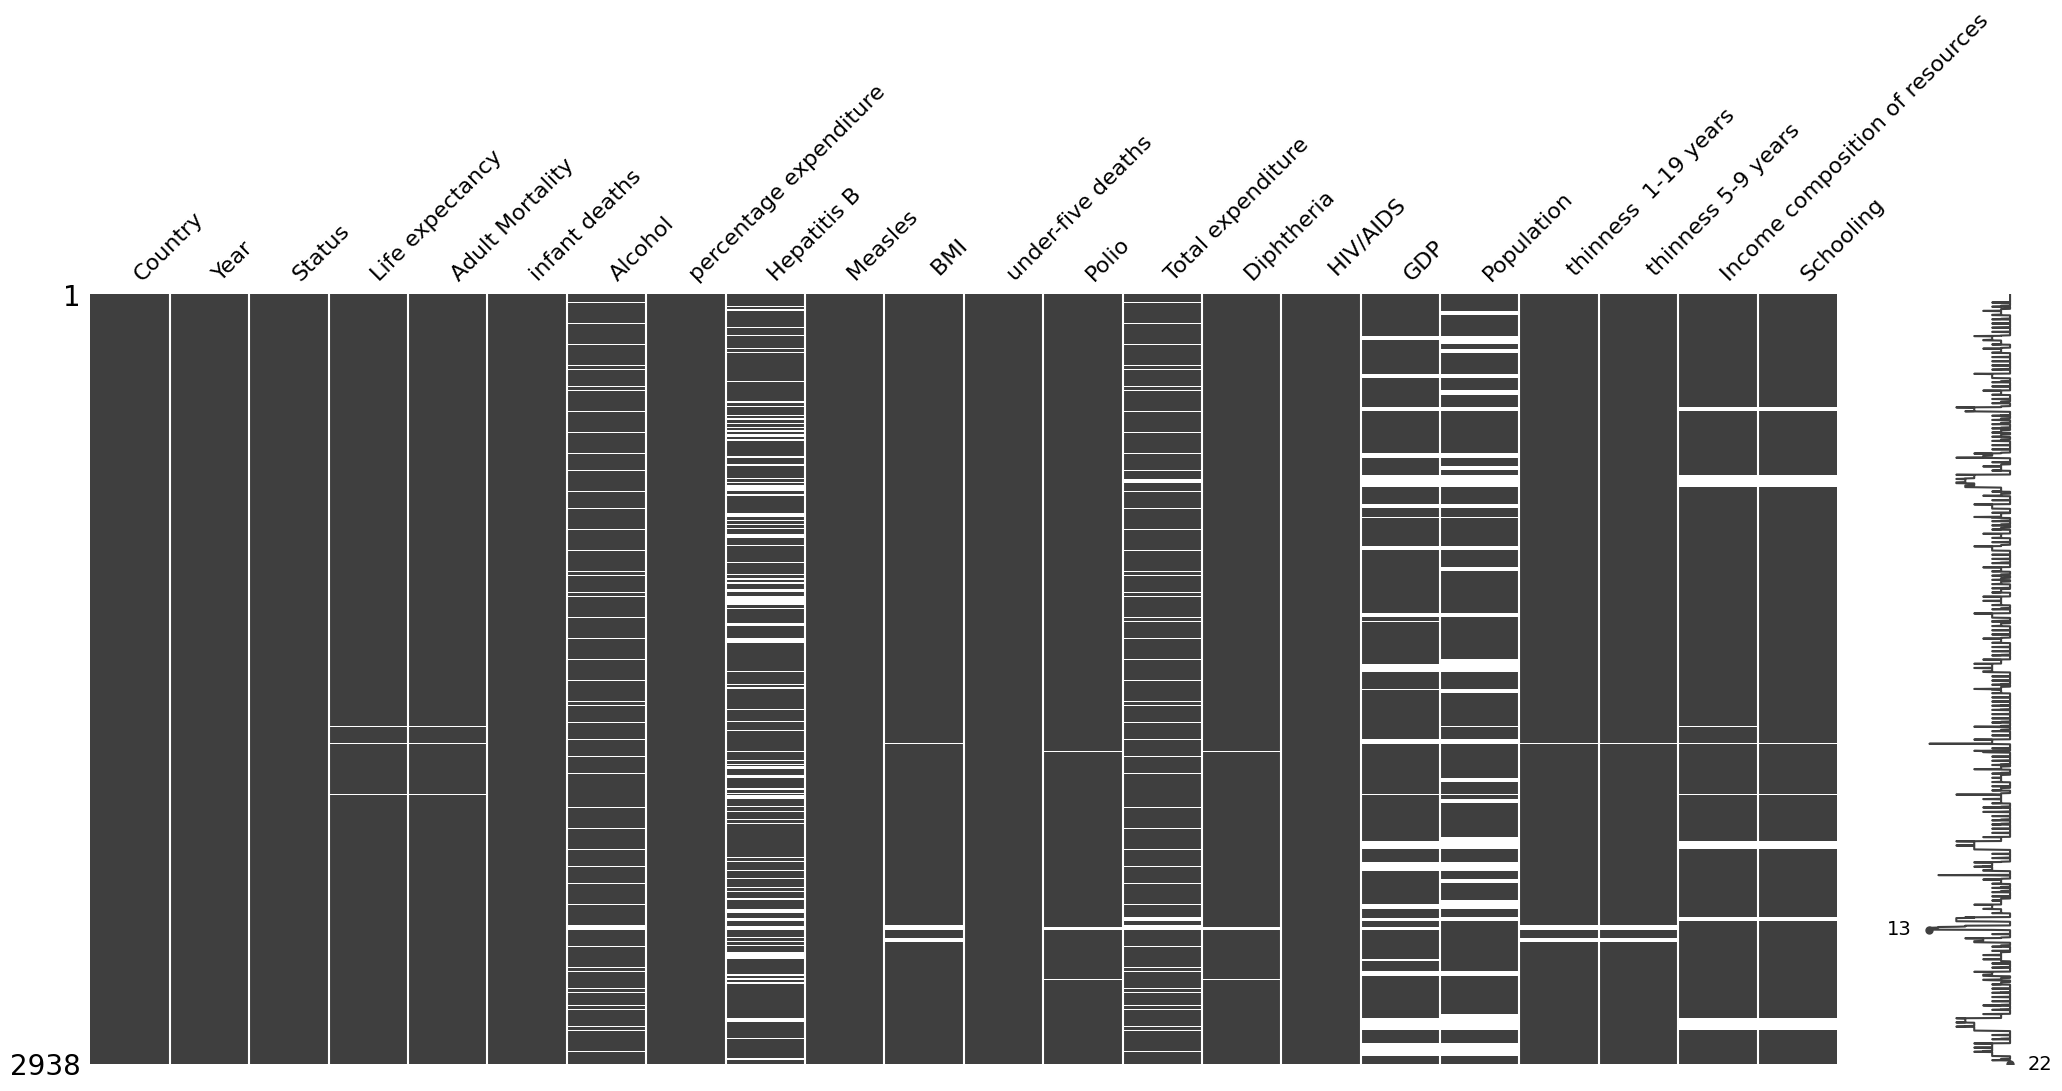

In [ ]:
# Visualiser la présence et la répartition des valeurs manquantes dans chaque colonne.
msno.matrix(df)
plt.show()


Observations : La matrice montre une répartition inégale des valeurs manquantes entre les variables. Certaines colonnes semblent entièrement renseignées, tandis que d'autres, notamment `Population`, `Hepatitis B` et `GDP`, présentent davantage de valeurs manquantes. On observe également des absences simultanées dans plusieurs colonnes. Une analyse quantitative permettra de confirmer ces constats et de mesurer précisément l'ampleur des données manquantes. Le nombre de colonne colonne manquant varie de 0 a 13. La sparkline de complétude montre que le nombre de variables renseignées par observation varie de 13 à 22. Certaines observations sont donc entièrement complètes, tandis que les moins renseignées présentent jusqu'à 9 valeurs manquantes sur les 22 variables.

In [ ]:
# Taux de variables manquantes par colonnes
taux = (df.isna().mean()
          .mul(100)
          .sort_values(ascending=False)
          .round(2))
print(taux)


Population                         22.19
Hepatitis B                        18.82
GDP                                15.25
Total expenditure                   7.69
Alcohol                             6.60
Income composition of resources     5.68
Schooling                           5.55
 thinness  1-19 years               1.16
 thinness 5-9 years                 1.16
 BMI                                1.16
Diphtheria                          0.65
Polio                               0.65
Life expectancy                     0.34
Adult Mortality                     0.34
infant deaths                       0.00
Status                              0.00
Country                             0.00
Year                                0.00
under-five deaths                   0.00
Measles                             0.00
percentage expenditure              0.00
 HIV/AIDS                           0.00
dtype: float64


In [ ]:
# Synthèse des valeurs manquantes par variable
missing_summary = pd.DataFrame({
    "Nombre de valeurs manquantes": df.isna().sum(),
    "Pourcentage (%)": (df.isna().mean() * 100).round(2)
})

# Tri par ordre décroissant en précisant la colonne cible
missing_summary.sort_values(by="Pourcentage (%)", ascending=False)


,Nombre de valeurs manquantes,Pourcentage (%)
Population,652,22.19
Hepatitis B,553,18.82
GDP,448,15.25
Total expenditure,226,7.69
Alcohol,194,6.60
Income composition of resources,167,5.68
Schooling,163,5.55
thinness 1-19 years,34,1.16
thinness 5-9 years,34,1.16
BMI,34,1.16


In [ ]:
# Exporter pour le rapport en gardant l'index (le nom des variables) comme première colonne
missing_summary.sort_values(by="Pourcentage (%)", ascending=False).to_excel("missing_summary.xlsx", index=True)

**Observations :** L'analyse des 2 938 observations révèle une répartition inégale des valeurs manquantes entre les 22 variables. Parmi celles-ci, 8 sont entièrement renseignées, tandis que `Population` (22,19 %), `Hepatitis B` (18,82 %) et `GDP` (15,25 %) présentent les proportions de valeurs manquantes les plus élevées.

Les autres variables sont moins touchées, avec des proportions inférieures à 8 %. Ces résultats confirment les tendances observées dans la matrice Missingno et permettent d'identifier les variables nécessitant une attention particulière lors de la préparation des données.

In [ ]:
# Calculer le pourcentage de valeurs manquantes par pays et par variable
taux_par_pays = (
    df.groupby('Country')
      .apply(lambda groupe: groupe.isna().mean() * 100,
             include_groups=False)
      .round(2)
)

taux_par_pays

,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,...,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Albania,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,...,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Algeria,0.0,0.0,0.0,0.0,0.0,6.25,0.0,25.00,0.0,0.0,...,0.0,6.25,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Angola,0.0,0.0,0.0,0.0,0.0,6.25,0.0,43.75,0.0,0.0,...,0.0,6.25,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Antigua and Barbuda,0.0,0.0,0.0,0.0,0.0,6.25,0.0,6.25,0.0,0.0,...,0.0,6.25,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Venezuela (Bolivarian Republic of),0.0,0.0,0.0,0.0,0.0,6.25,0.0,0.00,0.0,0.0,...,0.0,6.25,0.0,0.0,100.0,100.0,0.0,0.0,0.0,0.0
Viet Nam,0.0,0.0,0.0,0.0,0.0,6.25,0.0,18.75,0.0,0.0,...,0.0,6.25,0.0,0.0,100.0,100.0,0.0,0.0,0.0,0.0
Yemen,0.0,0.0,0.0,0.0,0.0,6.25,0.0,0.00,0.0,0.0,...,0.0,6.25,0.0,0.0,100.0,100.0,0.0,0.0,0.0,0.0


Observation : L’analyse des valeurs manquantes par pays porte sur 193 pays et 21 variables. Elle révèle une répartition inégale des données manquantes selon les pays et les variables. Certaines présentent des absences ponctuelles (6,25 %, 25 %, etc.), tandis que d’autres, notamment Population et GDP, sont entièrement manquantes (100 %) pour certains pays. Ces résultats montrent l’intérêt d’examiner les valeurs manquantes par pays, au-delà des taux globaux.

In [ ]:
# Examiner les valeurs manquantes des trois variables les plus touchées
taux_par_pays[
    ['Population', 'Hepatitis B', 'GDP']
].sort_values('Population', ascending=False)

,Population,Hepatitis B,GDP
Country,,,
Antigua and Barbuda,100.0,6.25,0.0
Dominica,100.0,0.00,0.0
Barbados,100.0,6.25,0.0
Bahrain,100.0,0.00,0.0
Bahamas,100.0,6.25,100.0
...,...,...,...
Uruguay,0.0,0.00,0.0
Vanuatu,0.0,0.00,0.0
Uzbekistan,0.0,12.50,0.0


In [ ]:
# Identifier les pays sans aucune donnée de population
taux_par_pays.loc[
    taux_par_pays['Population'] == 100,
    ['Population', 'Hepatitis B', 'GDP']
]

,Population,Hepatitis B,GDP
Country,,,
Antigua and Barbuda,100.0,6.25,0.00
Bahamas,100.0,6.25,100.00
Bahrain,100.0,0.00,0.00
Barbados,100.0,6.25,0.00
Bolivia (Plurinational State of),100.0,0.00,100.00
Brunei Darussalam,100.0,0.00,0.00
Congo,100.0,43.75,100.00
Cook Islands,100.0,0.00,100.00
Cuba,100.0,0.00,0.00


In [ ]:
# Nombre et pourcentage de pays ayant 100 % de valeurs manquantes pour les variables 'Population', 'Hepatitis B', 'GDP'
variables = ['Population', 'Hepatitis B', 'GDP']

bilan_pays = pd.DataFrame({
    'Nombre de pays': (taux_par_pays[variables] == 100).sum(),
    'Pourcentage (%)': (
        (taux_par_pays[variables] == 100).mean() * 100
    ).round(2)
})

bilan_pays

,Nombre de pays,Pourcentage (%)
Population,48,24.87
Hepatitis B,9,4.66
GDP,30,15.54


**Observation :** Sur les 193 pays du jeu de données, 48 pays (24,87 %) ne disposent d'aucune donnée de population, contre 30 pays (15,54 %) pour le PIB (`GDP`) et 9 pays (4,66 %) pour la vaccination contre l'hépatite B.

Ces résultats montrent que les valeurs manquantes ne sont pas uniquement ponctuelles : certaines variables sont entièrement absentes pour plusieurs pays sur la période étudiée (2000–2015). Cette situation devra être prise en compte lors du traitement des données, notamment pour éviter l'exclusion systématique de pays entiers.

In [ ]:
# Calculer le pourcentage de valeurs manquantes par année et par variable
taux_par_annee = (
    df.groupby('Year')
      .apply(
          lambda groupe: groupe.isna().mean() * 100,
          include_groups=False
      )
      .round(2)
)

taux_par_annee

,Country,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
Year,,,,,,,,,,,,,,,,,,,,,
2000,0.0,0.0,0.00,0.00,0.0,0.55,0.0,53.55,0.0,1.09,...,1.64,2.19,1.64,0.0,15.85,21.86,1.09,1.09,5.46,5.46
2001,0.0,0.0,0.00,0.00,0.0,0.55,0.0,48.09,0.0,1.09,...,1.64,2.19,1.64,0.0,15.30,21.86,1.09,1.09,5.46,5.46
2002,0.0,0.0,0.00,0.00,0.0,0.55,0.0,38.25,0.0,1.09,...,1.09,2.19,1.09,0.0,15.30,21.86,1.09,1.09,5.46,5.46
2003,0.0,0.0,0.00,0.00,0.0,0.55,0.0,28.42,0.0,1.09,...,1.09,1.64,1.09,0.0,15.30,21.86,1.09,1.09,5.46,5.46
2004,0.0,0.0,0.00,0.00,0.0,0.55,0.0,24.59,0.0,1.09,...,1.09,1.64,1.09,0.0,14.75,21.86,1.09,1.09,5.46,5.46
2005,0.0,0.0,0.00,0.00,0.0,1.09,0.0,19.67,0.0,1.09,...,1.09,1.64,1.09,0.0,14.75,21.86,1.09,1.09,5.46,5.46
2006,0.0,0.0,0.00,0.00,0.0,0.55,0.0,17.49,0.0,1.09,...,0.55,1.64,0.55,0.0,14.75,21.86,1.09,1.09,5.46,5.46
2007,0.0,0.0,0.00,0.00,0.0,0.55,0.0,13.11,0.0,1.09,...,0.55,1.64,0.55,0.0,14.75,21.86,1.09,1.09,5.46,5.46
2008,0.0,0.0,0.00,0.00,0.0,0.55,0.0,10.93,0.0,1.09,...,0.55,1.64,0.55,0.0,14.75,21.86,1.09,1.09,5.46,5.46


Observations : Répartition des valeurs manquantes par année (2000–2015).

L'analyse met en évidence des tendances différentes selon les variables :
- Population : le taux de valeurs manquantes reste relativement stable, autour de 21,86 % entre 2000 et 2011, puis augmente légèrement jusqu'à 25,39 % en 2013. Cela confirme que les absences concernent principalement certains pays sur plusieurs années.
- GDP : les valeurs manquantes restent également relativement stables, généralement entre 14,75 % et 15,85 %, avec un maximum de 17,10 % en 2013.
- Hepatitis B : le taux diminue progressivement de 53,55 % en 2000 à 4,92 % en 2015, ce qui suggère une amélioration de la disponibilité des données au fil du temps.
- Alcohol et Total expenditure : les valeurs manquantes sont particulièrement concentrées en 2015, avec respectivement 96,72 % et 98,91 %.
- Life expectancy et Adult Mortality : les valeurs manquantes sont concentrées en 2013 (5,18 %), les autres années étant entièrement renseignées.

In [ ]:
# Comparer les taux de valeurs manquantes par année pour 'Population', 'Hepatitis B', 'GDP'
variables = ['Population', 'Hepatitis B', 'GDP']

taux_par_annee[variables]

,Population,Hepatitis B,GDP
Year,,,
2000,21.86,53.55,15.85
2001,21.86,48.09,15.30
2002,21.86,38.25,15.30
2003,21.86,28.42,15.30
2004,21.86,24.59,14.75
2005,21.86,19.67,14.75
2006,21.86,17.49,14.75
2007,21.86,13.11,14.75
2008,21.86,10.93,14.75


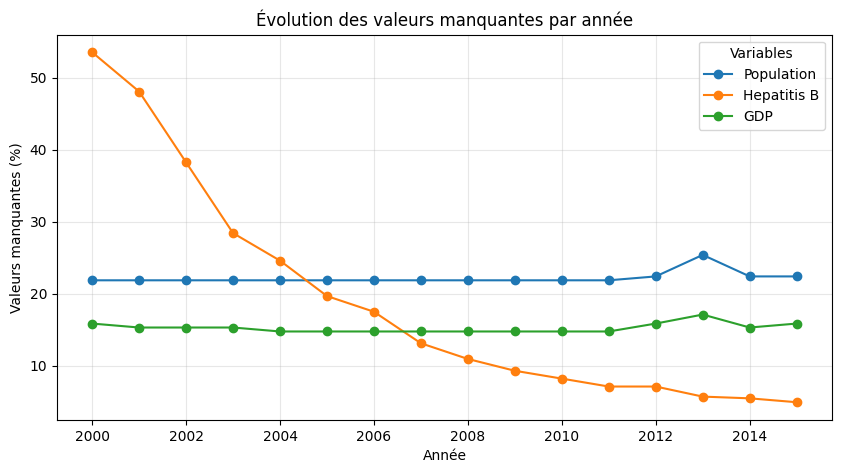

In [ ]:
# Visualiser l'évolution des valeurs manquantes par année
taux_par_annee[variables].plot(
    kind='line',
    marker='o',
    figsize=(10, 5),
    title='Évolution des valeurs manquantes par année'
)

plt.xlabel('Année')
plt.ylabel('Valeurs manquantes (%)')
plt.legend(title='Variables')
plt.grid(alpha=0.3)
plt.show()

**Observation :** Le graphique met en évidence trois tendances distinctes. Les taux de valeurs manquantes de `Population` et `GDP` restent relativement stables, autour de 22 % et 15 % respectivement, avec une légère augmentation en 2013. En revanche, `Hepatitis B` présente une diminution progressive et importante, passant de 53,55 % en 2000 à 4,92 % en 2015.

Cette évolution suggère une amélioration de la disponibilité des données sur la vaccination contre l'hépatite B au fil du temps, tandis que les absences de données démographiques et économiques semblent davantage liées à certains pays qu'aux années étudiées.

### 1.4 Recherche des doublons

In [ ]:
# Compter le nombre de lignes entièrement dupliquées
df.duplicated().sum()

np.int64(0)

In [ ]:
# Vérifier les doublons sur la combinaison pays-année
df.duplicated(subset=['Country', 'Year']).sum()

np.int64(0)

**Observation :** La recherche des doublons sur les 2 938 observations ne révèle aucune ligne entièrement dupliquée. De même, aucune duplication n'a été détectée sur la combinaison `Country` et `Year`, qui constitue l'identifiant logique de chaque observation.

Chaque pays dispose donc d'au plus une observation par année. Aucune suppression de doublons n'est nécessaire à ce stade.

### 1.5 Contrôle de cohérence

#### 1.5.1 Vérification des années, pays et catégories

In [ ]:
# Examiner les années présentes dans le jeu de données
sorted(df['Year'].unique())

[np.int64(2000),
 np.int64(2001),
 np.int64(2002),
 np.int64(2003),
 np.int64(2004),
 np.int64(2005),
 np.int64(2006),
 np.int64(2007),
 np.int64(2008),
 np.int64(2009),
 np.int64(2010),
 np.int64(2011),
 np.int64(2012),
 np.int64(2013),
 np.int64(2014),
 np.int64(2015)]

In [ ]:
# Identifier les observations hors de la période 2000–2015
df.loc[~df['Year'].between(2000, 2015), ['Country', 'Year']]

,Country,Year


In [ ]:
# Examiner les différentes modalités de Status
df['Status'].value_counts(dropna=False)

Status
Developing    2426
Developed      512
Name: count, dtype: int64

In [ ]:
# Compter les années distinctes disponibles pour chaque pays
annees_par_pays = (
    df.groupby('Country')['Year']
      .nunique()
      .sort_values()
)

annees_par_pays

Country
Dominica                               1
Cook Islands                           1
Niue                                   1
Nauru                                  1
Monaco                                 1
                                      ..
Venezuela (Bolivarian Republic of)    16
Viet Nam                              16
Yemen                                 16
Zambia                                16
Zimbabwe                              16
Name: Year, Length: 193, dtype: int64

In [ ]:
# Identifier les pays ayant moins de 16 années d'observation
annees_par_pays[annees_par_pays < 16]

Country
Dominica                 1
Cook Islands             1
Niue                     1
Nauru                    1
Monaco                   1
Marshall Islands         1
Saint Kitts and Nevis    1
Palau                    1
Tuvalu                   1
San Marino               1
Name: Year, dtype: int64

In [ ]:
# Compter les pays ayant moins de 16 années
(annees_par_pays < 16).sum()

np.int64(10)

In [ ]:
# Afficher les années disponibles pour les pays concernés
pays_incomplets = annees_par_pays[annees_par_pays < 16].index

df.loc[df['Country'].isin(pays_incomplets), ['Country', 'Year']].sort_values(
    ['Country', 'Year']
)

,Country,Year
624,Cook Islands,2013
769,Dominica,2013
1650,Marshall Islands,2013
1715,Monaco,2013
1812,Nauru,2013
1909,Niue,2013
1958,Palau,2013
2167,Saint Kitts and Nevis,2013
2216,San Marino,2013
2713,Tuvalu,2013


**Observation :** L'examen de la couverture temporelle révèle que 183 pays disposent de 16 années d'observation (2000–2015), tandis que 10 pays ne présentent qu'une seule observation, en 2013. Le jeu de données constitue donc un panel déséquilibré. Par ailleurs, aucune irrégularité liée aux espaces extérieurs n'a été détectée dans les valeurs de la variable `Status`.

Ces particularités seront prises en compte lors des analyses temporelles, notamment pour éviter de comparer des évolutions sur des périodes incomplètes.

#### 1.5.2 Vérification des plages de valeurs et des unités

In [ ]:
# Examiner les plages de valeurs des variables numériques
df.describe().loc[['min', 'max']].T

,min,max
Year,2000.00000,2.015000e+03
Life expectancy,36.30000,8.900000e+01
Adult Mortality,1.00000,7.230000e+02
infant deaths,0.00000,1.800000e+03
Alcohol,0.01000,1.787000e+01
percentage expenditure,0.00000,1.947991e+04
Hepatitis B,1.00000,9.900000e+01
Measles,0.00000,2.121830e+05
BMI,1.00000,8.730000e+01
under-five deaths,0.00000,2.500000e+03


Constat : 
Les variables de couverture vaccinale (Hepatitis B, Polio, Diphtheria) et de prévalence de la maigreur restent dans l'intervalle attendu de 0 à 100 %.
2. Les anomalies à examiner en priorité sont notamment :
- BMI : un maximum de 87,3 et un minimum de 1 semblent incompatibles avec une interprétation comme IMC moyen national.
- Population : une population nationale de 34 habitants est particulièrement suspecte.
- GDP : un PIB par habitant de 1,68 USD mérite une vérification.
- percentage expenditure : son unité reste indéterminée, comme nous l'avons déjà établi.

In [ ]:
# Identifier les observations correspondant aux valeurs extrêmes
variables = [' BMI ', 'Population', 'GDP']

for col in variables:
    print(f"\nVariable : {col}")

    print("Minimum :")
    print(df.loc[df[col].idxmin(), ['Country', 'Year', col]])

    print("Maximum :")
    print(df.loc[df[col].idxmax(), ['Country', 'Year', col]])


Variable :  BMI 
Minimum :
Country    Viet Nam
Year           2002
 BMI            1.0
Name: 2887, dtype: object
Maximum :
Country    Nauru
Year        2013
 BMI        87.3
Name: 1812, dtype: object

Variable : Population
Minimum :
Country       Maldives
Year              2003
Population        34.0
Name: 1614, dtype: object
Maximum :
Country              India
Year                  2014
Population    1293859294.0
Name: 1187, dtype: object

Variable : GDP
Minimum :
Country    Philippines
Year              2002
GDP            1.68135
Name: 2036, dtype: object
Maximum :
Country     Luxembourg
Year              2014
GDP        119172.7418
Name: 1539, dtype: object


**Observation :** L'examen des valeurs extrêmes révèle plusieurs incohérences potentielles. La variable `BMI` présente des valeurs de 1 au Viet Nam (2002) et de 87,3 à Nauru (2013), difficilement compatibles avec un IMC moyen national. La variable `Population` présente également une anomalie manifeste pour les Maldives en 2003, avec seulement 34 habitants dans le dataset, contre environ 296 491 selon la Banque mondiale.

Ces résultats suggèrent des problèmes de définition, d'échelle ou de qualité des données. Les observations concernées seront conservées dans le dataset original et examinées avant toute correction.

In [ ]:
df.columns

Index(['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure',
       'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population',
       ' thinness  1-19 years', ' thinness 5-9 years',
       'Income composition of resources', 'Schooling'],
      dtype='object')

In [ ]:
# Examiner les séries temporelles des variables suspectes
selection = {
    'Viet Nam': ' BMI ',
    'Nauru': ' BMI ',
    'Maldives': 'Population'
}

for pays, variable in selection.items():
    print(f"\n{pays} — {variable}")
    display(
        df.loc[df['Country'] == pays, ['Year', variable]]
          .sort_values('Year')
    )


Viet Nam —  BMI 


,Year,BMI
2889,2000,9.2
2888,2001,9.6
2887,2002,1.0
2886,2003,1.4
2885,2004,1.9
2884,2005,11.3
2883,2006,11.8
2882,2007,12.3
2881,2008,12.9
2880,2009,13.4



Nauru —  BMI 


,Year,BMI
1812,2013,87.3



Maldives — Population


,Year,Population
1617,2000,286.0
1616,2001,292.0
1615,2002,297.0
1614,2003,34.0
1613,2004,312.0
1612,2005,321.0
1611,2006,333.0
1610,2007,349.0
1609,2008,362.0
1608,2009,36.0


**Observation :** L'examen des séries temporelles révèle plusieurs incohérences potentielles dans les variables `BMI` et `Population`.

Pour `BMI`, des ruptures inhabituelles sont observées au Viet Nam entre 2002 et 2004, tandis que la valeur de 87,3 relevée à Nauru en 2013 paraît incompatible avec un IMC moyen national. Ces observations soulèvent des interrogations sur la fiabilité des valeurs et la définition de l'indicateur.

Pour `Population`, la série des Maldives présente d'importantes variations d'échelle, notamment en 2003, 2009, 2014 et 2015, suggérant des erreurs de transcription ou d'unité.

**Décision :** Conserver les données originales et approfondir la vérification de ces deux variables à partir de sources officielles. Un éventuel remplacement des valeurs de population et une clarification de la définition de `BMI` seront envisagés avant leur utilisation dans les analyses.

#### 1.5.3 Vérification des relations logiques entre variables

In [ ]:
# Identifier les observations où les décès infantiles dépassent
# les décès des enfants de moins de cinq ans

anomalies_deces = df.loc[
    df['infant deaths'] > df['under-five deaths '],
    ['Country', 'Year', 'infant deaths', 'under-five deaths ']
]

anomalies_deces

,Country,Year,infant deaths,under-five deaths


In [ ]:
# Examiner la corrélation entre les deux indicateurs de maigreur
df[[' thinness  1-19 years', ' thinness 5-9 years']].corr()

,thinness 1-19 years,thinness 5-9 years
thinness 1-19 years,1.000000,0.939102
thinness 5-9 years,0.939102,1.000000


In [ ]:
# Examiner les corrélations entre les couvertures vaccinales
variables_vaccination = ['Hepatitis B', 'Polio', 'Diphtheria ']

df[variables_vaccination].corr()

,Hepatitis B,Polio,Diphtheria
Hepatitis B,1.000000,0.486171,0.611495
Polio,0.486171,1.000000,0.673553
Diphtheria,0.611495,0.673553,1.000000


**Observations :**

- **Décès infantiles :** Aucune incohérence n'a été détectée entre `infant deaths` et `under-five deaths`. Pour toutes les observations, le nombre de décès d'enfants de moins d'un an ne dépasse pas celui des enfants de moins de cinq ans. La relation logique attendue est donc respectée.

- **Indicateurs de maigreur :** Les variables `thinness 1-19 years` et `thinness 5-9 years` présentent une très forte corrélation positive (r = 0,939). Elles évoluent généralement dans le même sens, ce qui est cohérent avec leur proximité thématique.

- **Couvertures vaccinales :** Les corrélations sont positives et modérées entre `Hepatitis B` et `Polio` (r = 0,486), entre `Hepatitis B` et `Diphtheria` (r = 0,611), ainsi qu'entre `Polio` et `Diphtheria` (r = 0,674). Ces résultats indiquent des associations positives entre les indicateurs, sans révéler à eux seuls d'incohérences.

**Conclusion :** Les contrôles réalisés ne mettent pas en évidence d'incohérence logique manifeste entre les variables examinées. Toutefois, les corrélations observées ne suffisent pas à garantir la validité des données ou l'exactitude de leurs définitions.

#### 1.5.4 Vérification de la cohérence temporelle par pays,

In [ ]:
# Variables à examiner
variables = [
    'GDP',
    'Population',
    ' BMI ',
    'percentage expenditure',
    'Total expenditure'
]

# Trier les observations par pays et par année
df_temp = df.sort_values(['Country', 'Year']).copy()

# Calculer les variations annuelles par pays
variations = df_temp.groupby('Country')[variables].pct_change(
    fill_method=None
) * 100

variations = variations.add_suffix('_variation_pct')

# Associer les variations aux pays et aux années
df_variations = pd.concat(
    [df_temp[['Country', 'Year']], variations],
    axis=1
)

df_variations.head()

,Country,Year,GDP_variation_pct,Population_variation_pct,BMI _variation_pct,percentage expenditure_variation_pct,Total expenditure_variation_pct
15,Afghanistan,2000,NaN,NaN,NaN,NaN,NaN
14,Afghanistan,2001,2.563705,909.839118,3.278689,1.436631,-4.878049
13,Afghanistan,2002,59.873003,640.947148,3.174603,59.695366,-0.512821
12,Afghanistan,2003,5.793361,-89.240859,3.076923,-34.335155,13.659794
11,Afghanistan,2004,10.271705,919.894234,2.985075,37.938441,-0.340136


Observation : L'analyse des variations annuelles met en évidence des ruptures temporelles importantes dans certaines variables, particulièrement Population. Pour l'Afghanistan, plusieurs variations dépassent 600 %, avec une chute de près de 90 % en 2003. Ces fluctuations sont difficilement compatibles avec une évolution démographique réelle et suggèrent des anomalies dans les données. Les autres variables présentent des variations plus modérées, bien que certaines nécessitent également une vérification.

In [ ]:
# Compter les variations annuelles supérieures à 50 % par variable
seuil = 50

bilan_ruptures = (
    df_variations.filter(like='_variation_pct')
    .abs()
    .gt(seuil)
    .sum()
    .sort_values(ascending=False)
)

bilan_ruptures

Population_variation_pct                1256
percentage expenditure_variation_pct    1217
GDP_variation_pct                        978
 BMI _variation_pct                      328
Total expenditure_variation_pct          104
dtype: int64

**Observation :** L'analyse des variations annuelles met en évidence de nombreuses ruptures supérieures à 50 % en valeur absolue, principalement pour `Population` (1 256), `percentage expenditure` (1 217) et `GDP` (978). Des variations importantes sont également observées pour `BMI` (328) et `Total expenditure` (104).

Ces résultats suggèrent des problèmes potentiels de cohérence temporelle, notamment des erreurs d'échelle ou de transcription. Toutefois, le seuil de 50 % étant exploratoire, les variations détectées ne constituent pas automatiquement des erreurs.

**Décision :** Approfondir la vérification des variables les plus concernées et comparer leurs valeurs à des sources fiables avant toute correction ou remplacement.

In [ ]:
# Calculer le nombre et le pourcentage de variations importantes
cols = df_variations.filter(like='_variation_pct')

bilan_ruptures_complet = pd.DataFrame({
    'Comparaisons valides': cols.notna().sum(),
    'Variations > 50 %': cols.abs().gt(50).sum()
})

bilan_ruptures_complet['Pourcentage (%)'] = (
    bilan_ruptures_complet['Variations > 50 %']
    / bilan_ruptures_complet['Comparaisons valides']
    * 100
).round(2)

bilan_ruptures_complet

,Comparaisons valides,Variations > 50 %,Pourcentage (%)
GDP_variation_pct,2327,978,42.03
Population_variation_pct,2141,1256,58.66
BMI _variation_pct,2715,328,12.08
percentage expenditure_variation_pct,2324,1217,52.37
Total expenditure_variation_pct,2521,104,4.13


**Observation :** L'analyse des variations annuelles révèle une fréquence élevée de ruptures supérieures à 50 % en valeur absolue, particulièrement pour `Population` (58,66 %), `percentage expenditure` (52,37 %) et `GDP` (42,03 %). Les proportions sont moins importantes pour `BMI` (12,08 %) et `Total expenditure` (4,13 %).

Ces résultats renforcent les soupçons d'incohérences temporelles et d'erreurs d'échelle dans certaines variables. Toutefois, les variations détectées ne constituent pas automatiquement des erreurs, le seuil de 50 % ayant été retenu à des fins exploratoires.

**Décision :** Prioriser la vérification des variables `Population`, `percentage expenditure` et `GDP`, puis examiner les anomalies de `BMI` et `Total expenditure` avant toute correction.

In [ ]:
import numpy as np

# Compter les variations infinies par variable
np.isinf(cols).sum()

GDP_variation_pct                       0
Population_variation_pct                0
 BMI _variation_pct                     0
percentage expenditure_variation_pct    4
Total expenditure_variation_pct         0
dtype: int64

**Observation :** La vérification des variations annuelles a permis d'identifier quatre valeurs infinies dans `percentage expenditure`, résultant de calculs de variation à partir de valeurs nulles. Leur exclusion ramène la proportion de ruptures supérieures à 50 % de 52,37 % à 52,28 %.

Cette correction technique ne modifie pas les données originales. Les résultats confirment que `Population`, `percentage expenditure` et `GDP` présentent les plus fortes proportions de ruptures temporelles et nécessitent une vérification prioritaire.

In [ ]:
# Exclure les variations infinies
cols_valides = cols.replace([np.inf, -np.inf], np.nan)

# Recalculer le bilan des ruptures
bilan_ruptures_final = pd.DataFrame({
    'Comparaisons valides': cols_valides.notna().sum(),
    'Variations > 50 %': cols_valides.abs().gt(50).sum()
})

bilan_ruptures_final['Pourcentage (%)'] = (
    bilan_ruptures_final['Variations > 50 %']
    / bilan_ruptures_final['Comparaisons valides']
    * 100
).round(2)

bilan_ruptures_final

,Comparaisons valides,Variations > 50 %,Pourcentage (%)
GDP_variation_pct,2327,978,42.03
Population_variation_pct,2141,1256,58.66
BMI _variation_pct,2715,328,12.08
percentage expenditure_variation_pct,2320,1213,52.28
Total expenditure_variation_pct,2521,104,4.13


**Observation :** Après exclusion des quatre variations infinies, l'analyse de la cohérence temporelle révèle une proportion élevée de variations annuelles supérieures à 50 % en valeur absolue pour `Population` (58,66 %), `percentage expenditure` (52,28 %) et `GDP` (42,03 %). Les proportions sont moins élevées pour `BMI` (12,08 %) et `Total expenditure` (4,13 %).

Ces résultats renforcent les soupçons d'erreurs d'échelle ou de transcription dans certaines variables, sans permettre de conclure que toutes les variations signalées sont erronées.

**Décision :** Prioriser la vérification des variables les plus concernées à partir de sources fiables, tout en conservant les données originales. Les corrections éventuelles devront être documentées et justifiées.

##### 1.5.5 Investigation approfondie des anomalies identifiées

In [ ]:
# Identifier les fortes variations annuelles de Population
anomalies_population = df_variations.loc[
    df_variations['Population_variation_pct'].abs() > 50,
    ['Country', 'Year', 'Population_variation_pct']
].copy()

# Trier les variations les plus importantes
anomalies_population = anomalies_population.sort_values(
    'Population_variation_pct',
    key=abs,
    ascending=False
)

anomalies_population.head(20)

,Country,Year,Population_variation_pct
1158,Hungary,2011,8.106995e+06
889,Ethiopia,2008,1.020699e+06
1234,Iraq,2015,1.012110e+06
1602,Maldives,2015,1.198098e+05
282,Benin,2005,1.028433e+05
486,Cameroon,2009,1.022951e+05
430,Burundi,2001,1.011327e+05
2709,Turkmenistan,2003,1.008484e+05
2012,Peru,2010,1.006430e+05
1874,Nicaragua,2002,9.983689e+04


**Observation :** L'examen des plus fortes variations annuelles de `Population` révèle des ruptures extrêmement importantes, atteignant plusieurs centaines de milliers, voire plusieurs millions de pour cent dans certains pays. Ces évolutions sont incompatibles avec des changements démographiques réels et suggèrent des erreurs récurrentes d'échelle ou de transcription.

Combinées au taux élevé de valeurs manquantes (22,19 %) et à l'absence complète de données pour 48 pays, ces anomalies remettent en question la fiabilité de la variable `Population` dans le dataset original.

**Décision envisagée :** Privilégier le remplacement de la variable `Population` par une série démographique officielle, homogène et documentée, notamment celle de la Banque mondiale, avant son utilisation dans les analyses.

In [ ]:
# Associer les variations suspectes aux valeurs originales
anomalies_population = anomalies_population.merge(
    df[['Country', 'Year', 'Population']],
    on=['Country', 'Year'],
    how='left'
)

anomalies_population.head(20)

,Country,Year,Population_variation_pct,Population
0,Hungary,2011,8.106995e+06,9971727.0
1,Ethiopia,2008,1.020699e+06,83184892.0
2,Iraq,2015,1.012110e+06,36115649.0
3,Maldives,2015,1.198098e+05,49163.0
4,Benin,2005,1.028433e+05,7982225.0
5,Cameroon,2009,1.022951e+05,19432541.0
6,Burundi,2001,1.011327e+05,6555829.0
7,Turkmenistan,2003,1.008484e+05,4655741.0
8,Peru,2010,1.006430e+05,29373646.0
9,Nicaragua,2002,9.983689e+04,5171734.0


**Observation :** L'examen des observations présentant les plus fortes variations annuelles de `Population` montre que certaines valeurs paraissent plausibles, malgré des variations extrêmement élevées. Ces ruptures pourraient donc provenir de valeurs incorrectes enregistrées l'année précédente, notamment en raison d'erreurs d'échelle ou de transcription.

Ces résultats confirment la nécessité d'examiner les séries temporelles complètes et non uniquement les observations signalées. Compte tenu de l'ampleur des anomalies et des valeurs manquantes, le remplacement de `Population` par une série officielle homogène constitue une option à privilégier lors de la préparation des données.

In [ ]:
# Comparer les populations de deux années consécutives
df.loc[
    (df['Country'] == 'Hungary') &
    (df['Year'].isin([2010, 2011])),
    ['Country', 'Year', 'Population']
].sort_values('Year')

,Country,Year,Population
1159,Hungary,2010,123.0
1158,Hungary,2011,9971727.0


**Observation :** L'examen de la série de population de la Hongrie confirme une incohérence majeure : la population passe de 123 habitants en 2010 à 9 971 727 en 2011. Cette rupture est manifestement incompatible avec l'évolution démographique réelle du pays et révèle une erreur dans les données de 2010.

Ce résultat confirme que certaines variations annuelles extrêmes proviennent de valeurs incorrectes, alors que les observations des années suivantes peuvent être plausibles.

**Décision :** Compte tenu des nombreuses incohérences et valeurs manquantes identifiées, privilégier le remplacement de la variable `Population` par une série officielle homogène, notamment celle de la Banque mondiale, lors de la préparation des données.

In [ ]:
# Identifier les fortes variations annuelles du PIB par habitant
anomalies_gdp = df_variations.loc[
    df_variations['GDP_variation_pct'].abs() > 50,
    ['Country', 'Year', 'GDP_variation_pct']
].copy()

# Trier selon l'ampleur des variations
anomalies_gdp = anomalies_gdp.sort_values(
    'GDP_variation_pct',
    key=abs,
    ascending=False
)

anomalies_gdp.head(20)

,Country,Year,GDP_variation_pct
1671,Mauritius,2011,109699.371857
1173,Iceland,2012,95825.420949
1295,Italy,2002,89333.795076
2119,Romania,2015,72870.170167
2078,Qatar,2008,12180.317853
1350,Kazakhstan,2011,11814.416340
1850,New Zealand,2010,11807.513450
2075,Qatar,2011,11574.204822
1273,Israel,2008,11366.821104
2691,Turkey,2005,11308.015261


In [ ]:
# Ajouter les valeurs originales du PIB par habitant
anomalies_gdp = anomalies_gdp.merge(
    df[['Country', 'Year', 'GDP']],
    on=['Country', 'Year'],
    how='left'
)

anomalies_gdp.head(20)

,Country,Year,GDP_variation_pct,GDP
0,Mauritius,2011,109699.371857,9197.269720
1,Iceland,2012,95825.420949,44333.851800
2,Italy,2002,89333.795076,22196.573600
3,Romania,2015,72870.170167,8958.788593
4,Qatar,2008,12180.317853,82967.372280
5,Kazakhstan,2011,11814.416340,11634.424220
6,New Zealand,2010,11807.513450,33691.348370
7,Qatar,2011,11574.204822,85948.746000
8,Israel,2008,11366.821104,29657.442100
9,Turkey,2005,11308.015261,7384.354661


In [ ]:
# Examiner l'évolution du PIB par habitant d'un pays
pays = 'Canada'

df.loc[
    df['Country'] == pays,
    ['Country', 'Year', 'GDP']
].sort_values('Year')

,Country,Year,GDP
511,Canada,2000,24124.16917
510,Canada,2001,23691.59472
509,Canada,2002,24167.84310
508,Canada,2003,28172.14883
507,Canada,2004,31979.87195
506,Canada,2005,36189.58838
505,Canada,2006,4386.69948
504,Canada,2007,44544.52680
503,Canada,2008,46596.33599
502,Canada,2009,4773.45436


**Observation :** L'investigation de la variable `GDP` révèle de nombreuses incohérences temporelles. Plusieurs pays présentent des variations annuelles extrêmement élevées, notamment Maurice (+109 699 % en 2011), l'Islande (+95 825 % en 2012) et l'Italie (+89 334 % en 2002). La série canadienne présente également plusieurs ruptures importantes.

Ces fluctuations suggèrent des erreurs récurrentes d'échelle ou de transcription, certaines valeurs annuelles pouvant être plausibles isolément malgré des variations aberrantes.

**Décision envisagée :** Privilégier le remplacement de `GDP` par une série officielle homogène de PIB par habitant, notamment celle de la Banque mondiale, après vérification des définitions, unités et années de référence.

In [ ]:
# Identifier les fortes variations annuelles des dépenses de santé
anomalies_depenses = df_variations.loc[
    df_variations['percentage expenditure_variation_pct'].abs() > 50,
    ['Country', 'Year', 'percentage expenditure_variation_pct']
].copy()

# Trier selon l'ampleur des variations
anomalies_depenses = anomalies_depenses.sort_values(
    'percentage expenditure_variation_pct',
    key=abs,
    ascending=False
)

anomalies_depenses.head(20)

,Country,Year,percentage expenditure_variation_pct
2932,Zimbabwe,2005,inf
1245,Iraq,2004,inf
2231,Sao Tome and Principe,2001,inf
2412,South Sudan,2012,inf
1671,Mauritius,2011,8.502068e+05
1173,Iceland,2012,9.664315e+04
1295,Italy,2002,9.224857e+04
2691,Turkey,2005,7.343281e+04
2583,Thailand,2001,6.377217e+04
337,Botswana,2014,5.919464e+04


In [ ]:
# Ajouter les valeurs originales des dépenses de santé et du PIB
anomalies_depenses = anomalies_depenses.merge(
    df[['Country', 'Year', 'percentage expenditure', 'GDP']],
    on=['Country', 'Year'],
    how='left'
)

anomalies_depenses.head(20)

,Country,Year,percentage expenditure_variation_pct,percentage expenditure,GDP
0,Zimbabwe,2005,inf,8.717409,444.765750
1,Iraq,2004,inf,44.120596,1391.816923
2,Sao Tome and Principe,2001,inf,3.841229,51.216381
3,South Sudan,2012,inf,38.338232,958.455810
4,Mauritius,2011,8.502068e+05,918.807245,9197.269720
5,Iceland,2012,9.664315e+04,6818.546407,44333.851800
6,Italy,2002,9.224857e+04,2883.334911,22196.573600
7,Turkey,2005,7.343281e+04,832.955206,7384.354661
8,Thailand,2001,6.377217e+04,176.062520,1893.145377
9,Botswana,2014,5.919464e+04,662.802194,7497.762376


In [ ]:
# Identifier les ruptures communes aux deux variables
ruptures_communes = df_variations.loc[
    (df_variations['GDP_variation_pct'].abs() > 50) &
    (df_variations['percentage expenditure_variation_pct'].abs() > 50),
    [
        'Country',
        'Year',
        'GDP_variation_pct',
        'percentage expenditure_variation_pct'
    ]
]

# Compter les ruptures simultanées
print("Nombre de ruptures communes :", len(ruptures_communes))

ruptures_communes.head(20)

Nombre de ruptures communes : 929


,Country,Year,GDP_variation_pct,percentage expenditure_variation_pct
13,Afghanistan,2002,59.873003,59.695366
10,Afghanistan,2005,-88.457619,-90.921537
9,Afghanistan,2006,977.577173,1136.563969
4,Afghanistan,2011,-88.517277,-91.092915
3,Afghanistan,2012,954.435312,1001.634744
28,Albania,2003,-86.951295,-85.916836
27,Albania,2004,1174.023829,1407.157056
26,Albania,2005,-88.448883,-87.832320
25,Albania,2006,-87.415300,-87.766683
24,Albania,2007,933.715019,876.530783


**Observation :** L'analyse croisée des variations annuelles de `GDP` et de `percentage expenditure` révèle 929 ruptures communes supérieures à 50 % en valeur absolue. Ces correspondances représentent 94,99 % des ruptures détectées pour `GDP` et 76,59 % de celles de `percentage expenditure`, après exclusion des variations infinies.

Cette forte coïncidence suggère une dépendance dans la construction des deux variables ou des erreurs d'échelle communes. Toutefois, elle ne permet pas d'établir la nature exacte de leur relation ni de confirmer l'unité de `percentage expenditure`.

**Décision :** Approfondir l'examen du rapport entre les deux variables et rechercher la définition d'origine de `percentage expenditure` avant d'envisager sa correction, son remplacement ou son exclusion des analyses.

In [ ]:
# Examiner le rapport entre les deux variables
df_ratio = df[['Country', 'Year', 'GDP', 'percentage expenditure']].copy()

df_ratio['ratio_pct'] = (
    df_ratio['percentage expenditure'] / df_ratio['GDP'] * 100
)

# Éviter les rapports infinis
df_ratio['ratio_pct'] = df_ratio['ratio_pct'].replace(
    [np.inf, -np.inf], np.nan
)

df_ratio.head()

,Country,Year,GDP,percentage expenditure,ratio_pct
0,Afghanistan,2015,584.259210,71.279624,12.20
1,Afghanistan,2014,612.696514,73.523582,12.00
2,Afghanistan,2013,631.744976,73.219243,11.59
3,Afghanistan,2012,669.959000,78.184215,11.67
4,Afghanistan,2011,63.537231,7.097109,11.17


**Observation :** L'analyse du rapport entre `percentage expenditure` et `GDP` met en évidence une évolution relativement régulière pour l'Afghanistan, malgré des ruptures importantes dans les valeurs des deux variables. Ce constat, également observé pour le Canada, renforce l'hypothèse d'une dépendance mathématique ou d'erreurs d'échelle communes.

**Décision :** La définition et l'unité de `percentage expenditure` ne sont pas encore établies. Une comparaison avec les indicateurs officiels de dépenses de santé sera nécessaire avant de décider de son maintien, de sa correction ou de son remplacement.

#### 1.6 Identification des valeurs atypiques ou aberrantes

In [ ]:
# Examiner la distribution des variables numériques
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,2938.0,2.007519e+03,4.613841e+00,2000.00000,2004.000000,2.008000e+03,2.012000e+03,2.015000e+03
Life expectancy,2928.0,6.922493e+01,9.523867e+00,36.30000,63.100000,7.210000e+01,7.570000e+01,8.900000e+01
Adult Mortality,2928.0,1.647964e+02,1.242921e+02,1.00000,74.000000,1.440000e+02,2.280000e+02,7.230000e+02
infant deaths,2938.0,3.030395e+01,1.179265e+02,0.00000,0.000000,3.000000e+00,2.200000e+01,1.800000e+03
Alcohol,2744.0,4.602861e+00,4.052413e+00,0.01000,0.877500,3.755000e+00,7.702500e+00,1.787000e+01
percentage expenditure,2938.0,7.382513e+02,1.987915e+03,0.00000,4.685343,6.491291e+01,4.415341e+02,1.947991e+04
Hepatitis B,2385.0,8.094046e+01,2.507002e+01,1.00000,77.000000,9.200000e+01,9.700000e+01,9.900000e+01
Measles,2938.0,2.419592e+03,1.146727e+04,0.00000,0.000000,1.700000e+01,3.602500e+02,2.121830e+05
BMI,2904.0,3.832125e+01,2.004403e+01,1.00000,19.300000,4.350000e+01,5.620000e+01,8.730000e+01
under-five deaths,2938.0,4.203574e+01,1.604455e+02,0.00000,0.000000,4.000000e+00,2.800000e+01,2.500000e+03


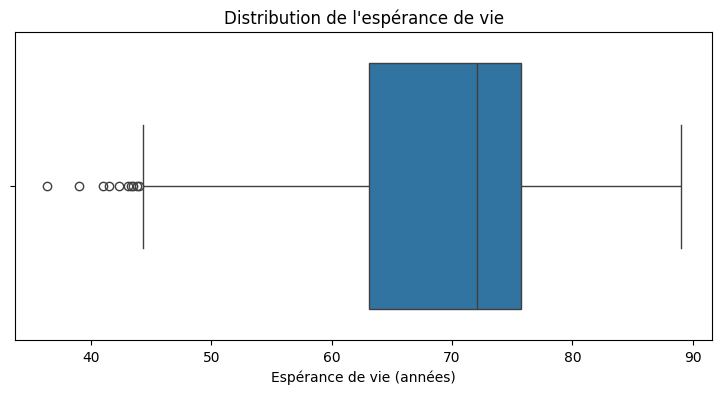

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualiser la distribution de l'espérance de vie
plt.figure(figsize=(9, 4))

sns.boxplot(
    x=df['Life expectancy ']
)

plt.title("Distribution de l'espérance de vie")
plt.xlabel("Espérance de vie (années)")
plt.show()

In [ ]:
# Sélectionner la variable à analyser
col = 'Life expectancy '

# Calculer les quartiles
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

# Calculer l'écart interquartile
IQR = Q3 - Q1

# Définir les bornes de détection
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

# Identifier les observations atypiques
valeurs_atypiques = df.loc[
    (df[col] < borne_inf) | (df[col] > borne_sup),
    ['Country', 'Year', col]
]

# Afficher les bornes et le nombre de valeurs atypiques
print("Borne inférieure :", round(borne_inf, 2))
print("Borne supérieure :", round(borne_sup, 2))
print("Nombre de valeurs atypiques :", len(valeurs_atypiques))

valeurs_atypiques

Borne inférieure : 44.2
Borne supérieure : 94.6
Nombre de valeurs atypiques : 10


,Country,Year,Life expectancy
1127,Haiti,2010,36.3
1583,Malawi,2002,44.0
1584,Malawi,2001,43.5
1585,Malawi,2000,43.1
2307,Sierra Leone,2005,43.3
2308,Sierra Leone,2004,42.3
2309,Sierra Leone,2003,41.5
2311,Sierra Leone,2001,41.0
2312,Sierra Leone,2000,39.0
2921,Zambia,2000,43.8


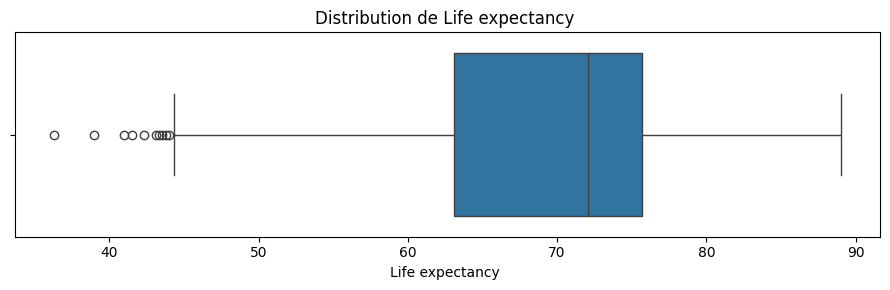

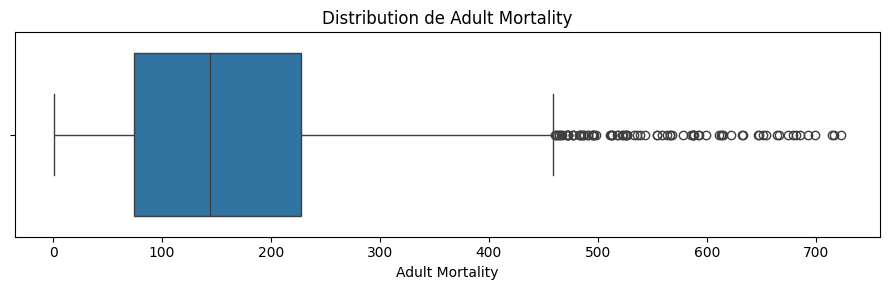

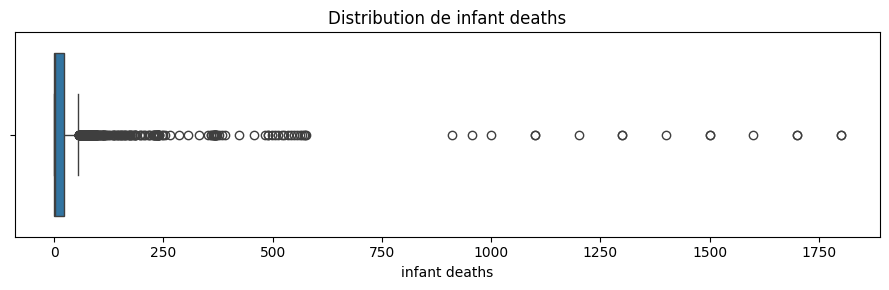

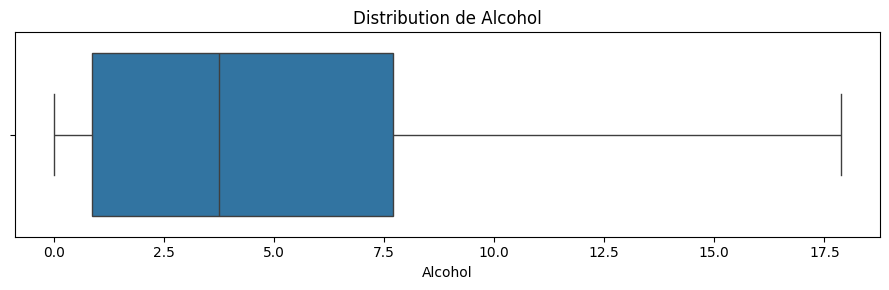

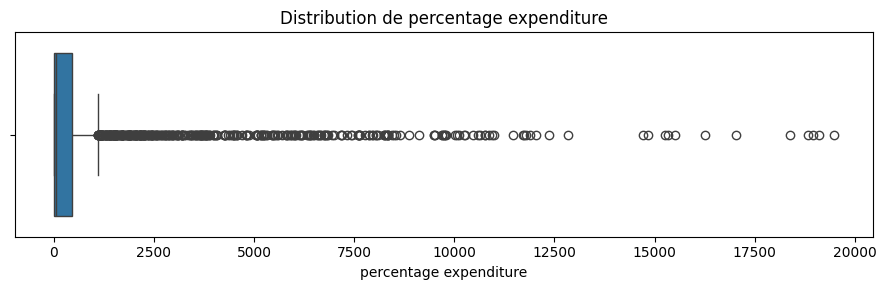

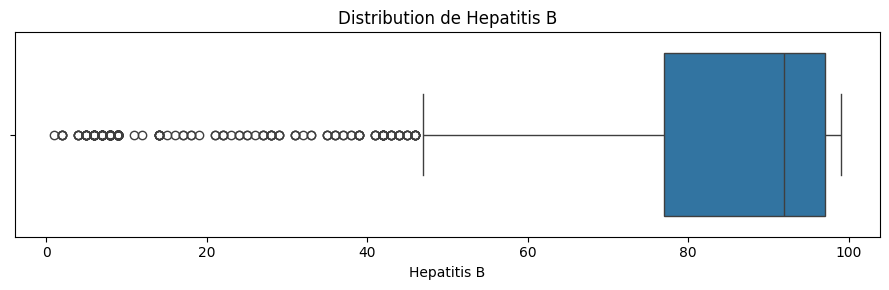

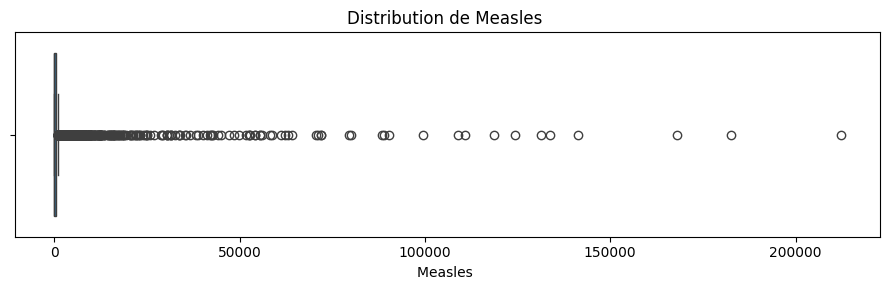

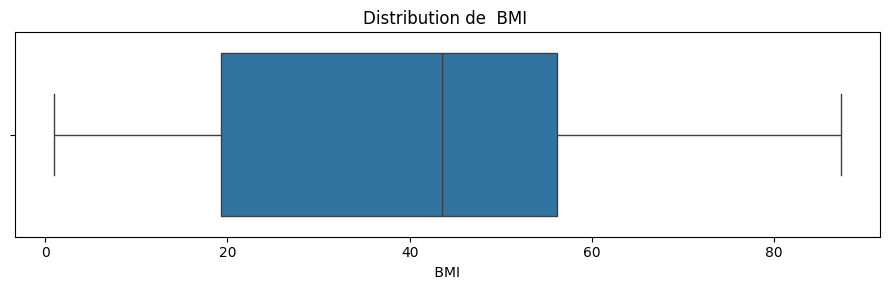

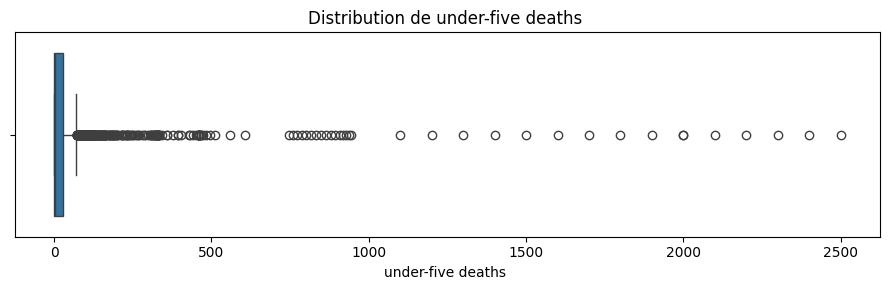

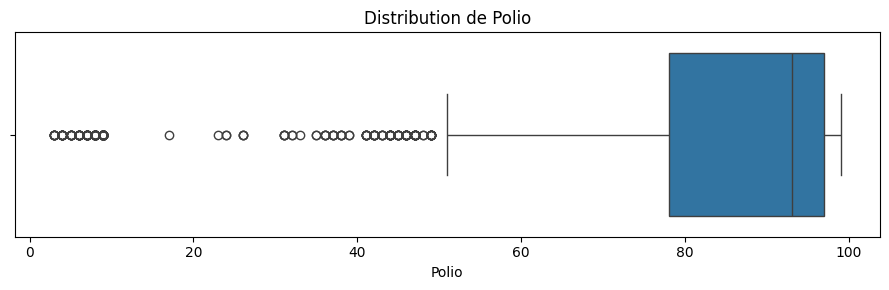

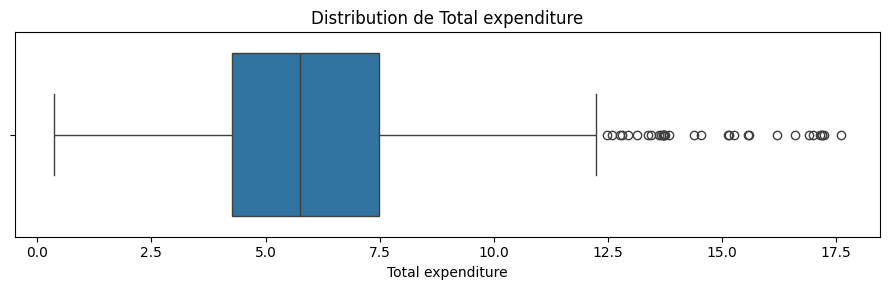

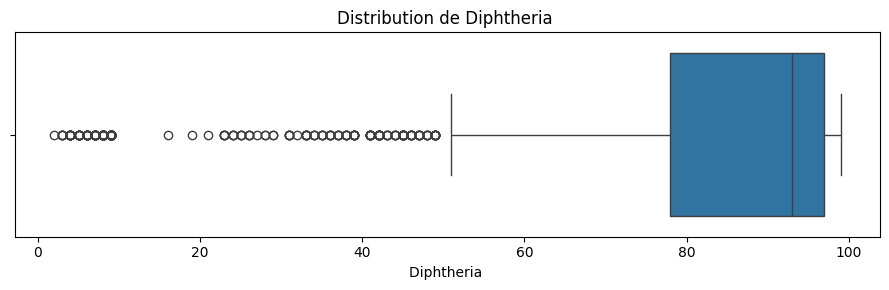

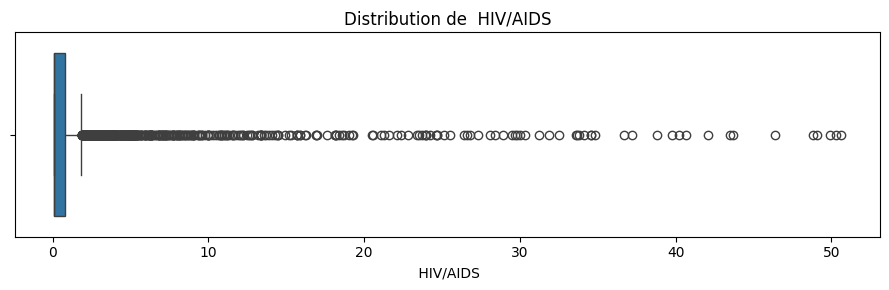

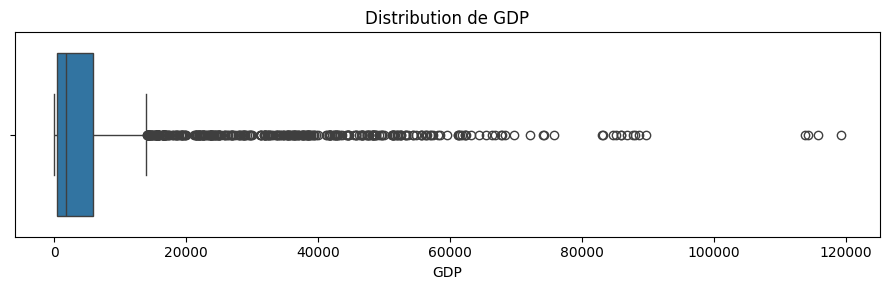

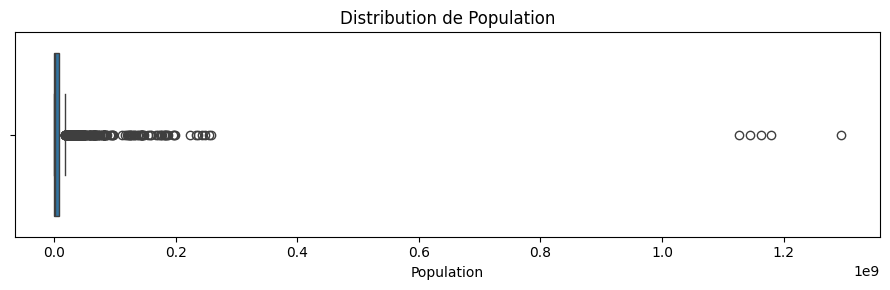

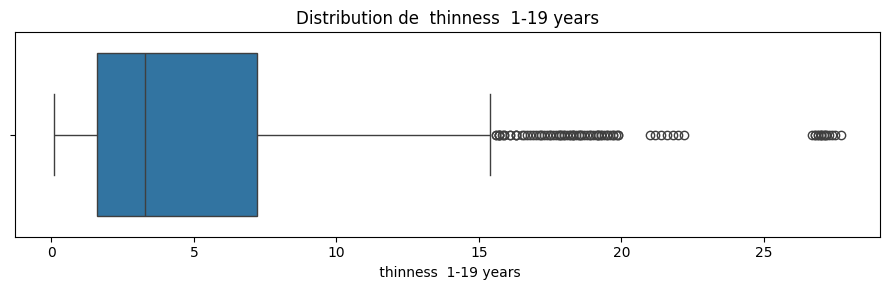

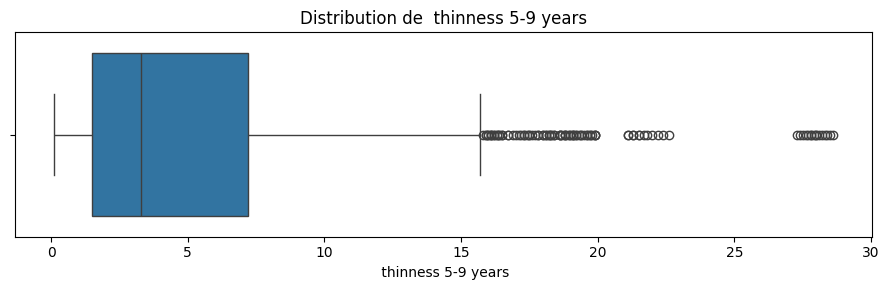

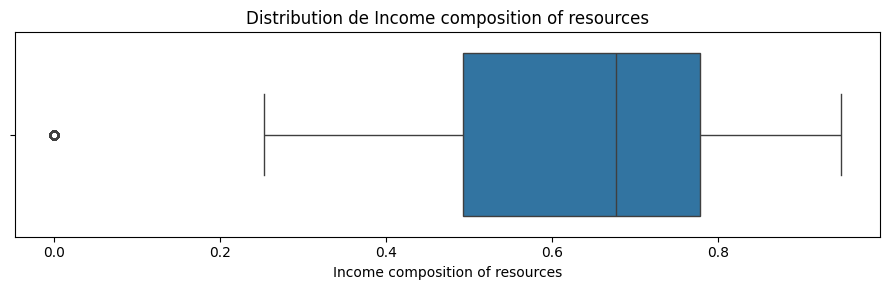

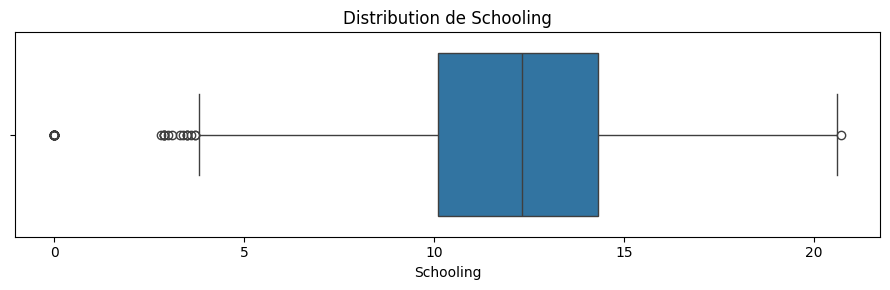

In [ ]:
# Générer automatiquement les boxplots de toutes les variables numériques

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sélectionner automatiquement les variables numériques
variables_num = df.select_dtypes(include='number').columns

# Exclure les variables numériques non pertinentes pour l'analyse IQR
variables_num = df.select_dtypes(include='number').columns.drop(
    ['Year'],
    errors='ignore'
)

# Générer un boxplot pour chaque variable
for col in variables_num:
    plt.figure(figsize=(9, 3))

    sns.boxplot(x=df[col].dropna())

    plt.title(f"Distribution de {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [ ]:
# Détecter les valeurs atypiques avec une boucle for

# Initialiser une liste pour stocker les résultats
resultats_iqr = []

# Parcourir chaque variable numérique
for col in variables_num:

    # Calculer les quartiles
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # Calculer l'écart interquartile
    IQR = Q3 - Q1

    # Déterminer les bornes
    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    # Identifier les observations atypiques
    masque = (df[col] < borne_inf) | (df[col] > borne_sup)

    # Calculer le nombre et le pourcentage
    nombre = masque.sum()
    taux = nombre / df[col].count() * 100 if df[col].count() else 0

    # Enregistrer les résultats
    resultats_iqr.append({
        'Variable': col,
        'Borne inférieure': round(borne_inf, 2),
        'Borne supérieure': round(borne_sup, 2),
        'Nombre atypiques': nombre,
        'Pourcentage (%)': round(taux, 2)
    })

# Construire le tableau de synthèse
bilan_iqr = pd.DataFrame(resultats_iqr)

# Trier les variables les plus concernées
bilan_iqr = bilan_iqr.sort_values(
    'Pourcentage (%)',
    ascending=False
)

bilan_iqr

,Variable,Borne inférieure,Borne supérieure,Nombre atypiques,Pourcentage (%)
6,Measles,-540.38,900.62,542,18.45
12,HIV/AIDS,-0.95,1.85,542,18.45
13,GDP,-7706.37,14081.11,365,14.66
8,under-five deaths,-42.00,70.00,394,13.41
4,percentage expenditure,-650.59,1096.81,389,13.24
14,Population,-10641055.38,18257207.62,294,12.86
2,infant deaths,-33.00,55.00,315,10.72
5,Hepatitis B,47.00,127.00,254,10.65
11,Diphtheria,49.50,125.50,298,10.21
9,Polio,49.50,125.50,279,9.56


In [ ]:
# Approche vectorisée avec pandas

# Sélectionner les variables numériques à analyser
variables_num = df.select_dtypes(include='number').drop(
    columns='Year',
    errors='ignore'
)

# Calculer les quartiles de toutes les variables
Q1 = variables_num.quantile(0.25)
Q3 = variables_num.quantile(0.75)

# Calculer les bornes IQR
IQR = Q3 - Q1
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

# Identifier toutes les valeurs atypiques
masque_atypiques = (
    variables_num.lt(borne_inf) |
    variables_num.gt(borne_sup)
)

# Produire un rapport synthétique
rapport_atypiques = pd.DataFrame({
    'Effectif valide': variables_num.count(),
    'Nombre atypiques': masque_atypiques.sum(),
    'Pourcentage (%)': (
        masque_atypiques.sum() / variables_num.count() * 100
    ).round(2),
    'Borne inférieure': borne_inf.round(2),
    'Borne supérieure': borne_sup.round(2)
})

# Classer les variables selon le taux de valeurs atypiques
rapport_atypiques = rapport_atypiques.sort_values(
    'Pourcentage (%)',
    ascending=False
)

rapport_atypiques

,Effectif valide,Nombre atypiques,Pourcentage (%),Borne inférieure,Borne supérieure
Measles,2938,542,18.45,-540.38,900.62
HIV/AIDS,2938,542,18.45,-0.95,1.85
GDP,2490,365,14.66,-7706.37,14081.11
under-five deaths,2938,394,13.41,-42.00,70.00
percentage expenditure,2938,389,13.24,-650.59,1096.81
Population,2286,294,12.86,-10641055.38,18257207.62
infant deaths,2938,315,10.72,-33.00,55.00
Hepatitis B,2385,254,10.65,47.00,127.00
Diphtheria,2919,298,10.21,49.50,125.50
Polio,2919,279,9.56,49.50,125.50


**Observation :**

L'application de la méthode IQR (1,5 × écart interquartile) aux 19 variables numériques révèle des proportions variables de valeurs atypiques.

Les taux les plus élevés concernent `Measles` et `HIV/AIDS` (18,45 % chacune), suivies de `GDP` (14,66 %), `under-five deaths` (13,41 %), `percentage expenditure` (13,24 %) et `Population` (12,86 %).

Les indicateurs de couverture vaccinale (`Hepatitis B`, `Diphtheria`, `Polio`) présentent également des proportions de valeurs atypiques comprises entre 9,56 % et 10,65 %.

À l'inverse, `Life expectancy` présente seulement 10 observations atypiques (0,34 %), tandis qu'aucune valeur n'est signalée pour `BMI` et `Alcohol`.

**Interprétation :**

Ces résultats mettent en évidence une forte hétérogénéité des distributions, particulièrement pour les indicateurs épidémiologiques, démographiques et économiques. Certaines valeurs extrêmes peuvent refléter des différences réelles entre pays, tandis que d'autres peuvent être associées aux incohérences précédemment identifiées.

L'absence de valeurs atypiques pour `BMI`, malgré certaines valeurs suspectes relevées lors du contrôle de cohérence, montre également les limites de la méthode IQR globale.

**Décision :**

Conserver les observations à ce stade et utiliser les résultats de l'IQR comme outil de signalement statistique. Les valeurs détectées feront l'objet d'investigations ciblées avant toute décision de correction, de remplacement ou d'exclusion.